NAME:V.GAGAN CHANDRA TEJ
ROLL NO:2403A52222
BATCH:09
LAB:11

In [2]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 1. Load and preprocess the dataset

In [3]:
# Auto-detect the dataset root (folder that contains train/ and test/ with NORMAL & PNEUMONIA)
def find_root(base="/kaggle/input"):
    for dp, dn, _ in os.walk(base):
        if "train" in dn and "test" in dn:
            if os.path.isdir(os.path.join(dp, "train", "NORMAL")):
                return dp
    raise FileNotFoundError("Chest X-ray dataset not found. Add it via 'Add Input' in the notebook.")

ROOT = find_root()
print("Dataset root:", ROOT)
for split in ["train", "val", "test"]:
    p = os.path.join(ROOT, split)
    if os.path.isdir(p):
        print(split, {c: len(os.listdir(os.path.join(p, c))) for c in sorted(os.listdir(p)) if os.path.isdir(os.path.join(p, c))})

Dataset root: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray
train {'NORMAL': 1341, 'PNEUMONIA': 3875}
val {'NORMAL': 8, 'PNEUMONIA': 8}
test {'NORMAL': 234, 'PNEUMONIA': 390}


In [4]:
IMG_SIZE, BATCH = 224, 32

train_tf = transforms.Compose([
    transforms.Grayscale(1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.9, 1.0)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])
eval_tf = transforms.Compose([
    transforms.Grayscale(1),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]),
])

# The official 'val' folder has only 16 images, so we make our own 85/15 train/val split from train/
full_train_aug = datasets.ImageFolder(os.path.join(ROOT, "train"), transform=train_tf)
full_train_eval = datasets.ImageFolder(os.path.join(ROOT, "train"), transform=eval_tf)
test_ds = datasets.ImageFolder(os.path.join(ROOT, "test"), transform=eval_tf)
classes = full_train_aug.classes
print("Classes:", full_train_aug.class_to_idx)

n = len(full_train_aug)
idx = np.random.RandomState(SEED).permutation(n)
n_val = int(0.15 * n)
val_idx, train_idx = idx[:n_val], idx[n_val:]

train_ds = Subset(full_train_aug, train_idx)
val_ds = Subset(full_train_eval, val_idx)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)
print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

# Class imbalance -> weighted loss
train_labels = np.array(full_train_aug.targets)[train_idx]
counts = np.bincount(train_labels)
class_weights = torch.tensor(len(train_labels) / (len(counts) * counts), dtype=torch.float32).to(device)
print("Train class counts:", dict(zip(classes, counts)), "| class weights:", class_weights.cpu().numpy().round(3))

Classes: {'NORMAL': 0, 'PNEUMONIA': 1}
Train: 4434 | Val: 782 | Test: 624
Train class counts: {'NORMAL': np.int64(1131), 'PNEUMONIA': np.int64(3303)} | class weights: [1.96  0.671]


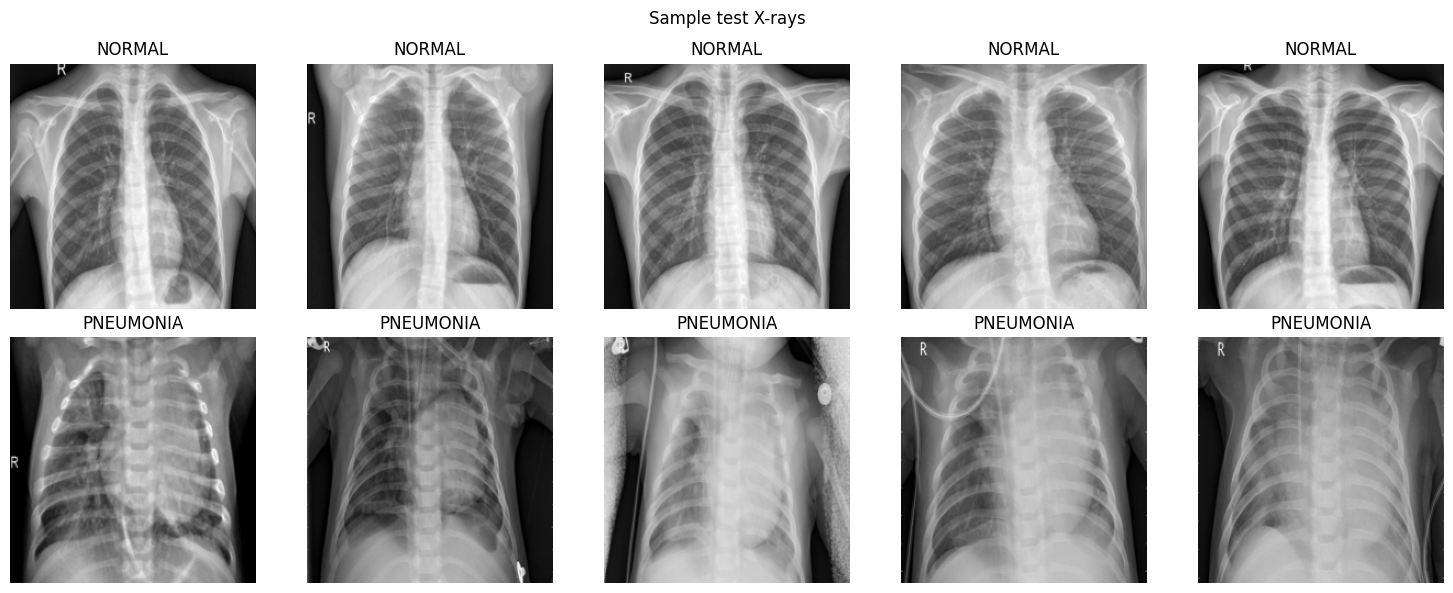

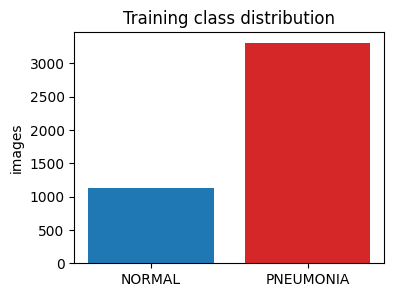

In [5]:
# Sample images + class distribution
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for r, c in enumerate(classes):
    ids = [i for i, t in enumerate(test_ds.targets) if t == r][:5]
    for k, i in enumerate(ids):
        img, _ = test_ds[i]
        axes[r, k].imshow(img.squeeze() * 0.5 + 0.5, cmap="gray"); axes[r, k].axis("off")
        axes[r, k].set_title(c)
plt.suptitle("Sample test X-rays"); plt.tight_layout(); plt.show()

plt.figure(figsize=(4, 3)); plt.bar(classes, counts, color=["tab:blue", "tab:red"])
plt.title("Training class distribution"); plt.ylabel("images"); plt.show()

## 2. Model — a CNN built so every layer can be inspected

In [6]:
class XrayCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                nn.ReLU(inplace=False), nn.MaxPool2d(2))
        self.block1 = block(1, 16)
        self.block2 = block(16, 32)
        self.block3 = block(32, 64)
        self.block4 = block(64, 128)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.5), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))
    def forward(self, x):
        x = self.block1(x); x = self.block2(x); x = self.block3(x); x = self.block4(x)
        return self.classifier(self.gap(x))

model = XrayCNN().to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

XrayCNN(
  (block1): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block4): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNo

## 3. Training

In [7]:
EPOCHS, LR = 15, 1e-3
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item(); total += x.size(0)
    return total_loss / total, correct / total

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val = float("inf")
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, True)
    vl, va = run_epoch(val_loader, False)
    scheduler.step(vl)
    for k, v in zip(history, [tl, vl, ta, va]): history[k].append(v)
    if vl < best_val:
        best_val = vl; torch.save(model.state_dict(), "best_model.pth")
    print(f"Epoch {ep:02d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.0f}s")

model.load_state_dict(torch.load("best_model.pth", map_location=device))
print("Loaded best model (val loss %.4f)" % best_val)

Epoch 01/15 | train loss 0.4237 acc 0.8124 | val loss 0.2815 acc 0.8581 | 67s
Epoch 02/15 | train loss 0.3189 acc 0.8651 | val loss 0.1881 acc 0.9220 | 47s
Epoch 03/15 | train loss 0.2929 acc 0.8796 | val loss 0.4509 acc 0.8721 | 45s
Epoch 04/15 | train loss 0.2556 acc 0.8978 | val loss 0.8903 acc 0.5332 | 45s
Epoch 05/15 | train loss 0.2459 acc 0.8999 | val loss 0.1367 acc 0.9361 | 45s
Epoch 06/15 | train loss 0.2114 acc 0.9127 | val loss 0.1483 acc 0.9066 | 45s
Epoch 07/15 | train loss 0.2085 acc 0.9136 | val loss 0.1211 acc 0.9386 | 45s
Epoch 08/15 | train loss 0.2128 acc 0.9127 | val loss 0.1873 acc 0.9348 | 45s
Epoch 09/15 | train loss 0.1825 acc 0.9299 | val loss 0.1778 acc 0.8875 | 45s
Epoch 10/15 | train loss 0.1805 acc 0.9265 | val loss 0.2368 acc 0.8696 | 45s
Epoch 11/15 | train loss 0.1741 acc 0.9344 | val loss 0.1138 acc 0.9412 | 46s
Epoch 12/15 | train loss 0.1668 acc 0.9348 | val loss 0.5312 acc 0.8619 | 45s
Epoch 13/15 | train loss 0.1578 acc 0.9400 | val loss 0.1817 acc

## 4. Evaluation

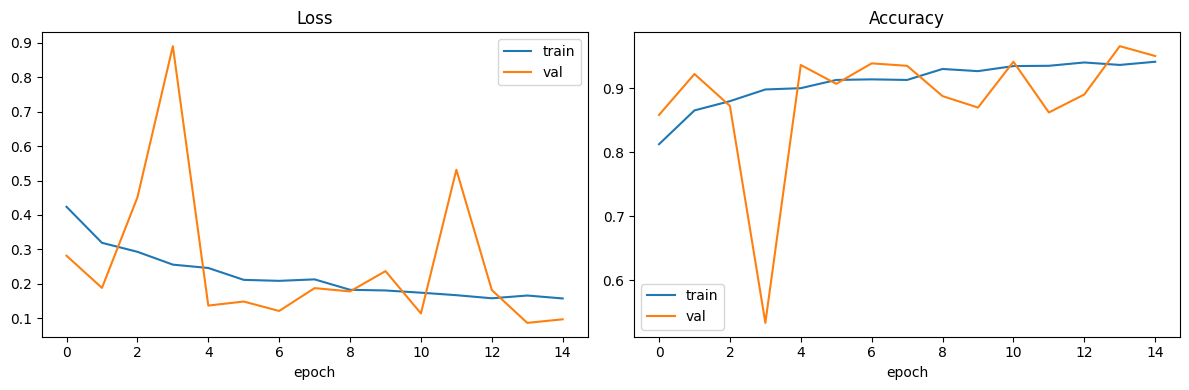

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

Accuracy : 0.8574
Precision: 0.8209  (PNEUMONIA = positive class)
Recall   : 0.9872
F1-score : 0.8964
ROC-AUC  : 0.9515

              precision    recall  f1-score   support

      NORMAL     0.9677    0.6410    0.7712       234
   PNEUMONIA     0.8209    0.9872    0.8964       390

    accuracy                         0.8574       624
   macro avg     0.8943    0.8141    0.8338       624
weighted avg     0.8760    0.8574    0.8494       624



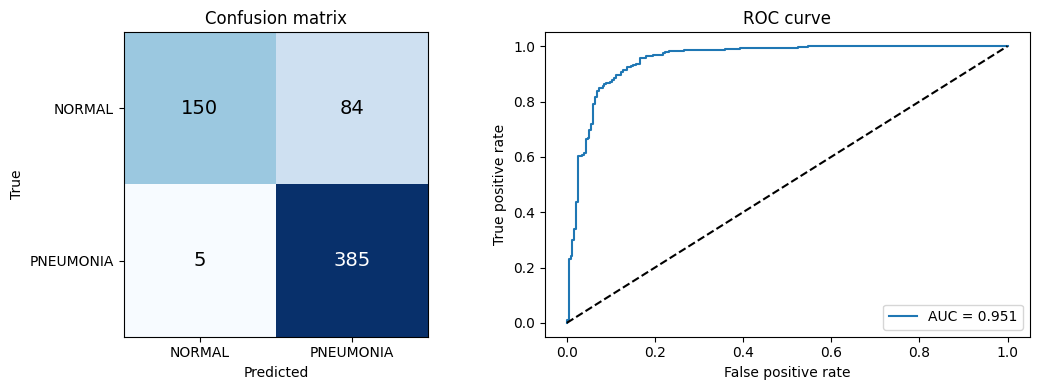

In [9]:
model.eval()
y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        p = F.softmax(model(x.to(device)), 1).cpu()
        y_prob += p[:, 1].tolist(); y_pred += p.argmax(1).tolist(); y_true += y.tolist()
y_true, y_pred, y_prob = map(np.array, (y_true, y_pred, y_prob))

print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}  (PNEUMONIA = positive class)")
print(f"Recall   : {recall_score(y_true, y_pred):.4f}")
print(f"F1-score : {f1_score(y_true, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_true, y_prob):.4f}\n")
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

cm = confusion_matrix(y_true, y_pred)
fpr, tpr, _ = roc_curve(y_true, y_prob)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(cm, cmap="Blues"); ax[0].set_title("Confusion matrix")
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(classes); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(classes)
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, y_prob):.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_title("ROC curve"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Visualization

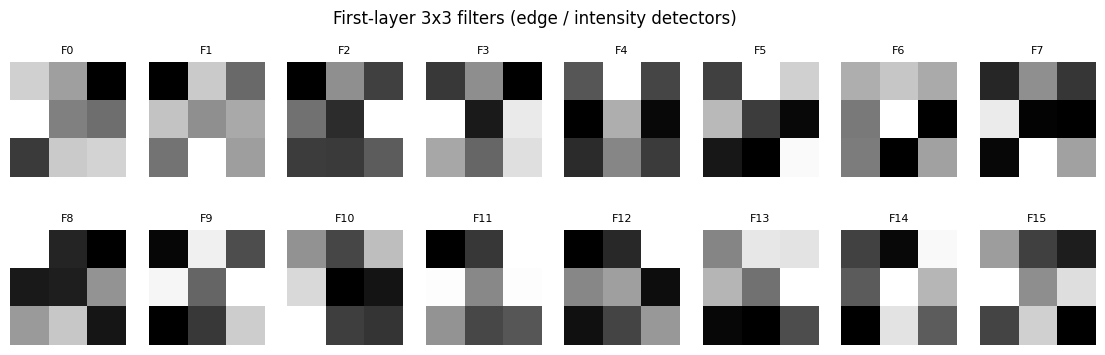

In [10]:
w = model.block1[0].weight.detach().cpu()   # (16, 1, 3, 3)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(w[i, 0], cmap="gray"); ax.axis("off"); ax.set_title(f"F{i}", fontsize=8)
plt.suptitle("First-layer 3x3 filters (edge / intensity detectors)"); plt.show()

### 5.2 Feature maps from every conv block

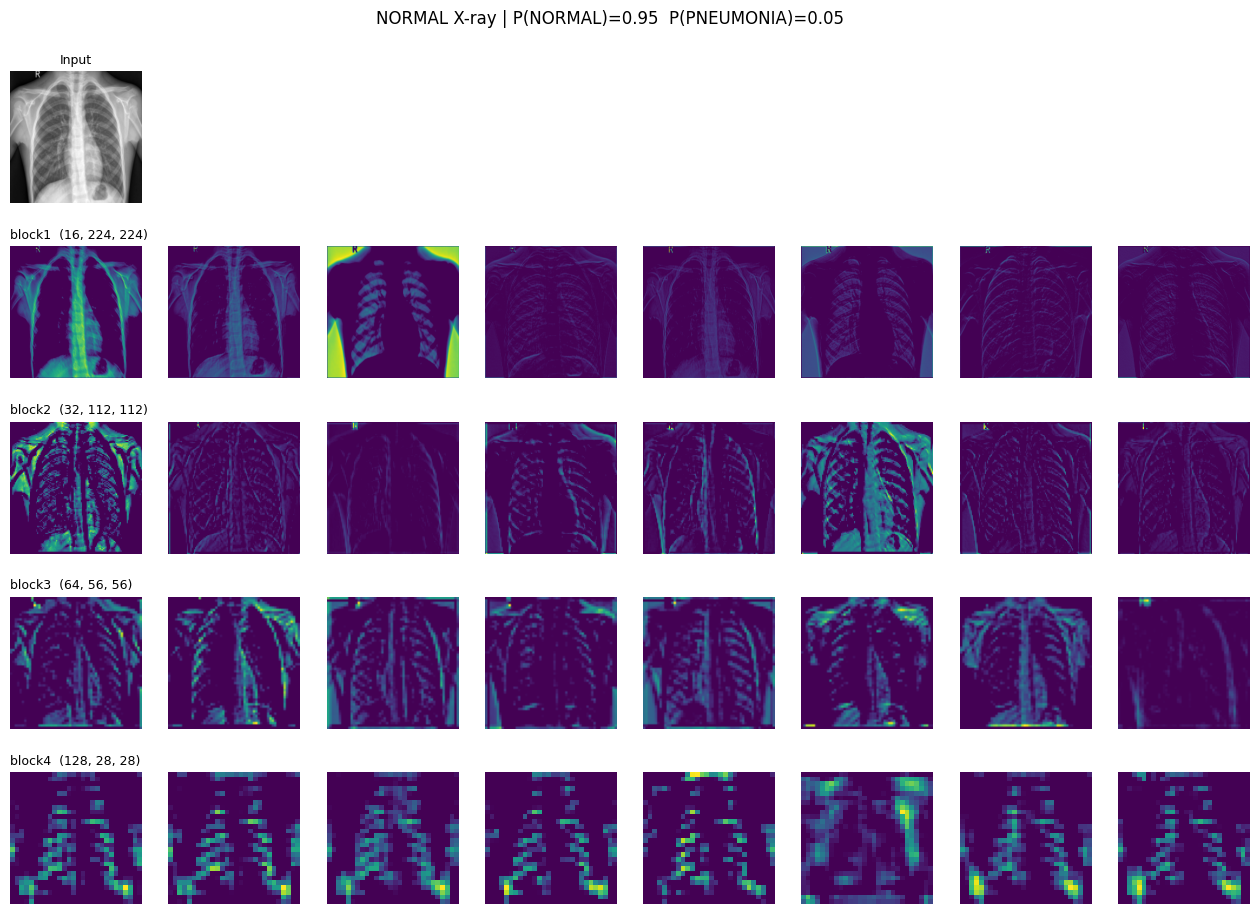

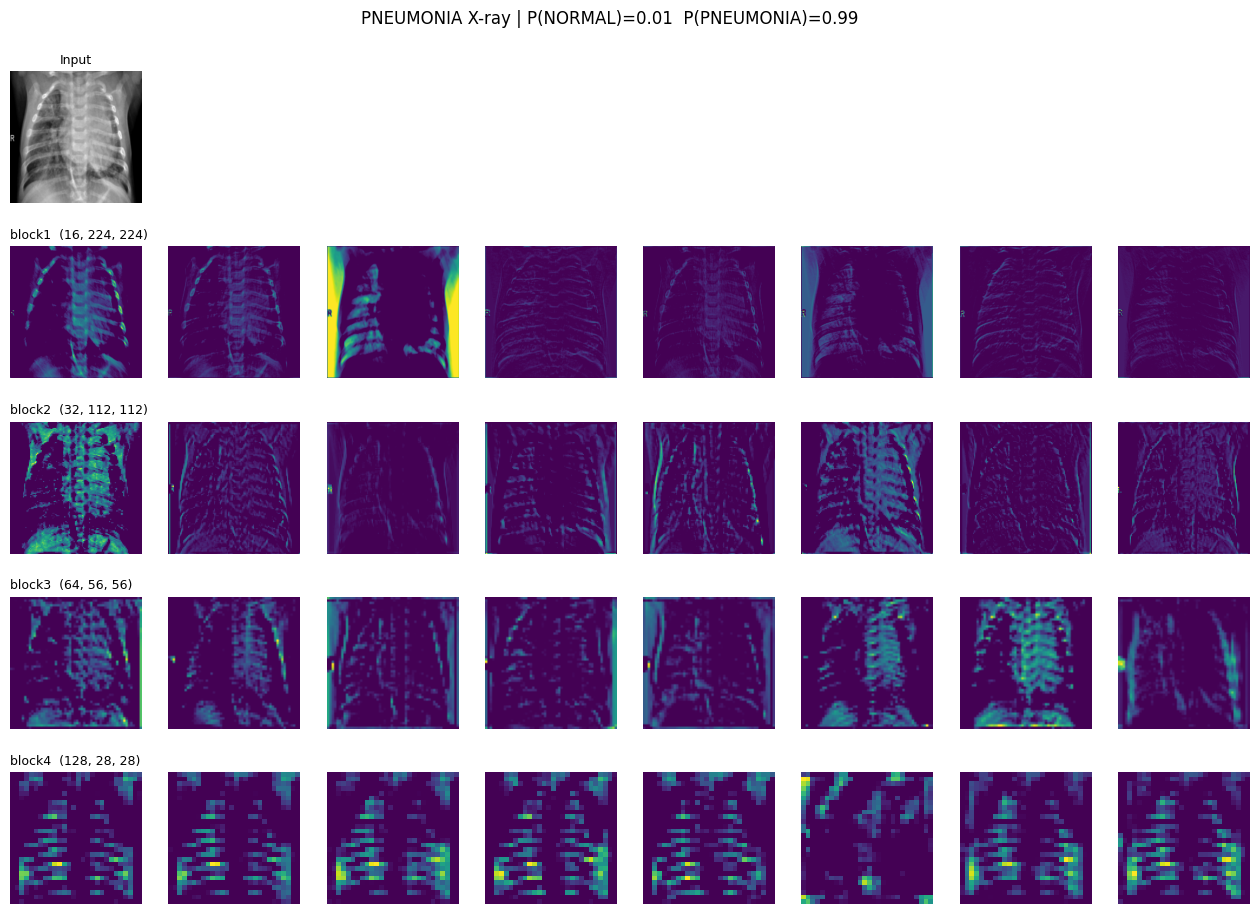

In [11]:
def get_sample(label, k=0):
    ids = [i for i, t in enumerate(test_ds.targets) if t == label]
    return test_ds[ids[k]][0].unsqueeze(0).to(device)

def get_feature_maps(x):
    feats, hooks = {}, []
    for name in ["block1", "block2", "block3", "block4"]:
        layer = getattr(model, name)[2]   # ReLU output
        hooks.append(layer.register_forward_hook(lambda m, i, o, n=name: feats.__setitem__(n, o.detach().cpu())))
    model.eval()
    with torch.no_grad(): out = model(x)
    for h in hooks: h.remove()
    return feats, F.softmax(out, 1)[0].cpu()

def show_feature_maps(x, title, n_maps=8):
    feats, probs = get_feature_maps(x)
    fig, axes = plt.subplots(5, n_maps, figsize=(2 * n_maps, 11))
    for c in range(n_maps):
        axes[0, c].axis("off")
    axes[0, 0].imshow(x[0, 0].cpu() * 0.5 + 0.5, cmap="gray"); axes[0, 0].set_title("Input", fontsize=9)
    for r, name in enumerate(["block1", "block2", "block3", "block4"], start=1):
        f = feats[name][0]
        for c in range(n_maps):
            axes[r, c].imshow(f[c], cmap="viridis"); axes[r, c].axis("off")
            if c == 0: axes[r, c].set_title(f"{name}  {tuple(f.shape)}", fontsize=9, loc="left")
    plt.suptitle(f"{title} | P(NORMAL)={probs[0]:.2f}  P(PNEUMONIA)={probs[1]:.2f}", y=0.93)
    plt.show()

show_feature_maps(get_sample(0), "NORMAL X-ray")
show_feature_maps(get_sample(1), "PNEUMONIA X-ray")

### 5.3 Saliency maps
**Vanilla gradient saliency:** gradient of the predicted-class score w.r.t. the input pixels — shows which pixels change the prediction most.  
**Grad-CAM:** weights the last conv feature maps by their pooled gradients to give a coarse, region-level heatmap.

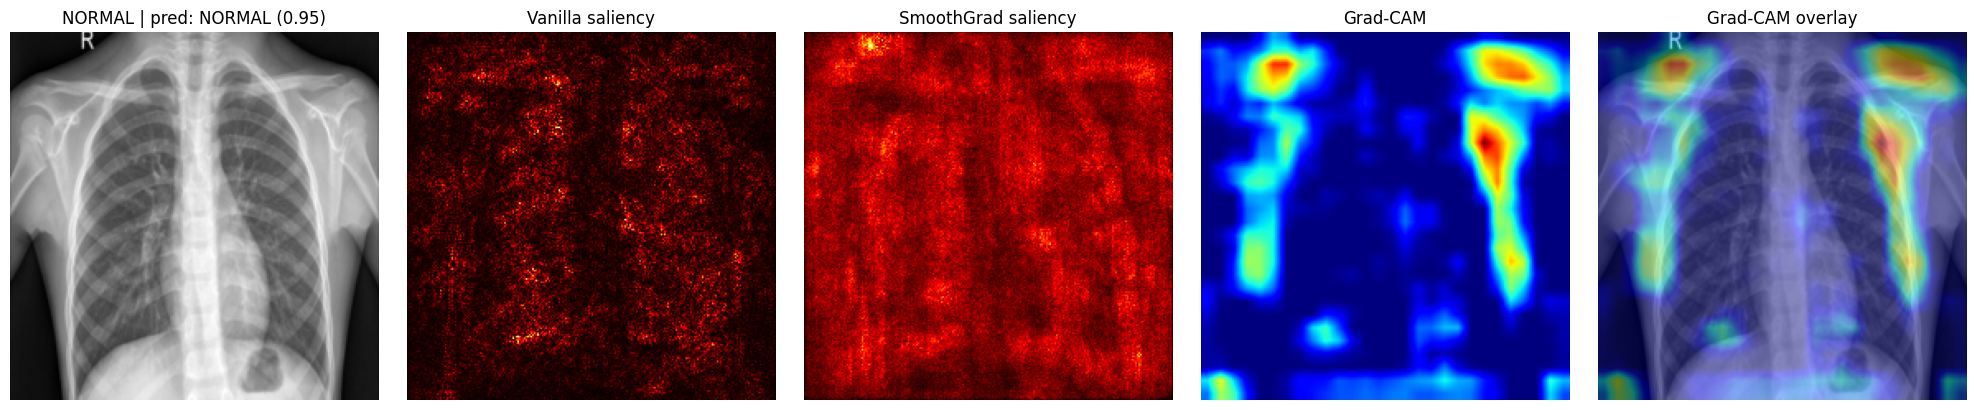

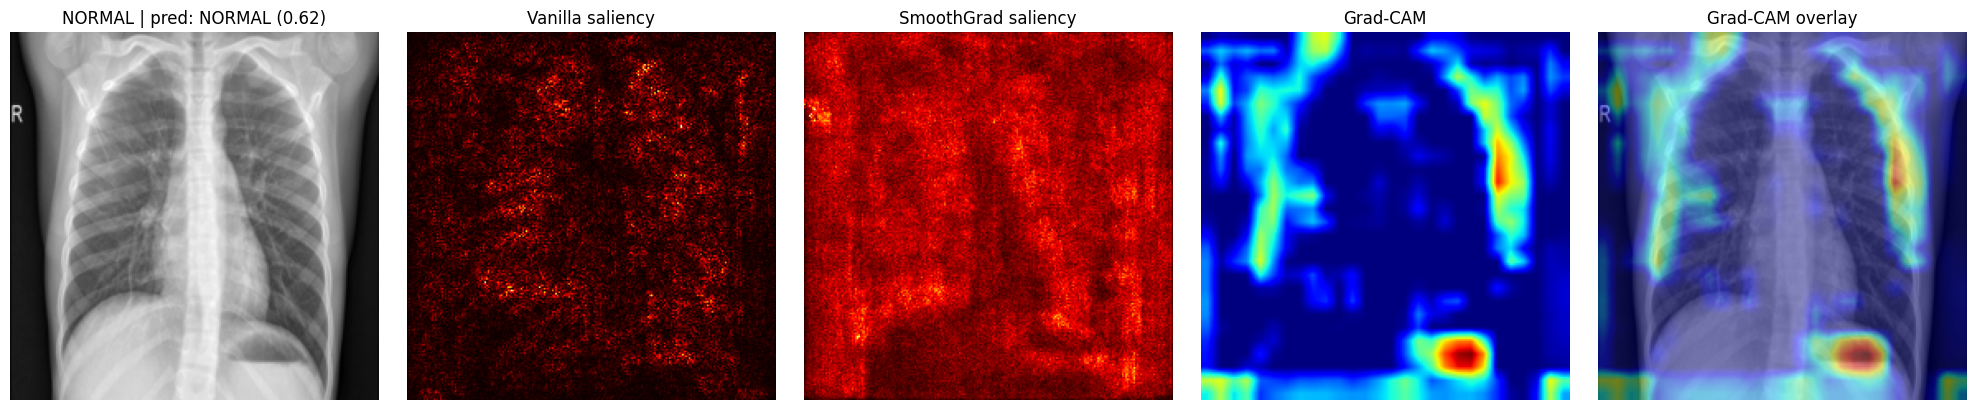

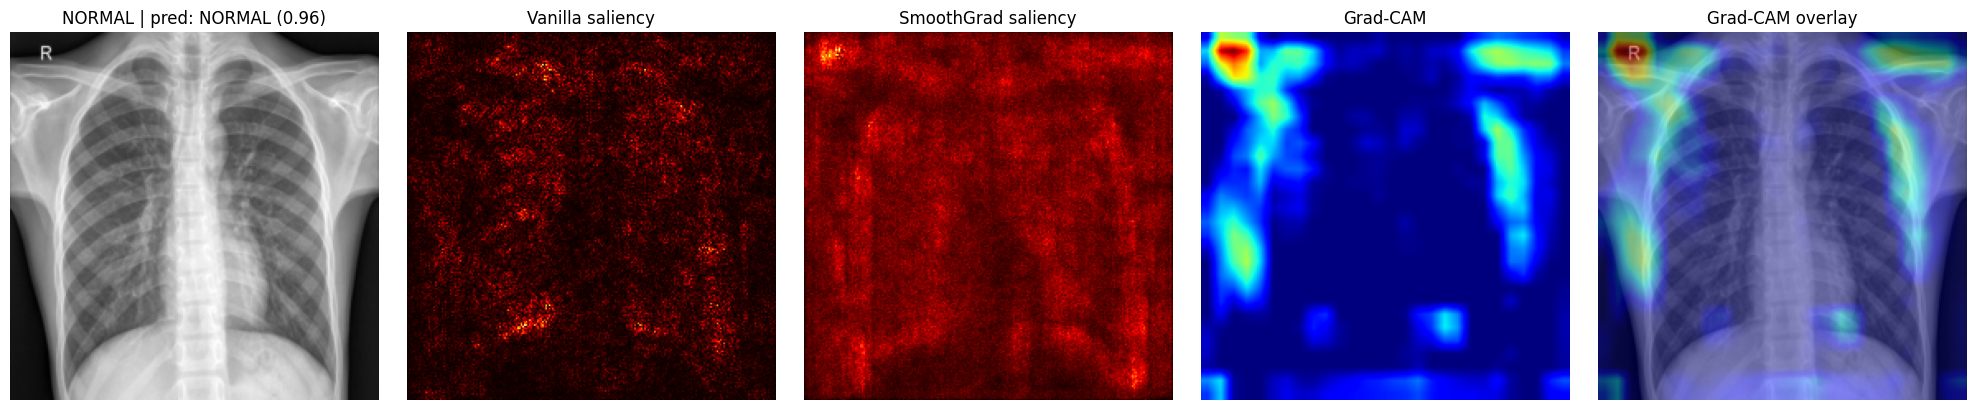

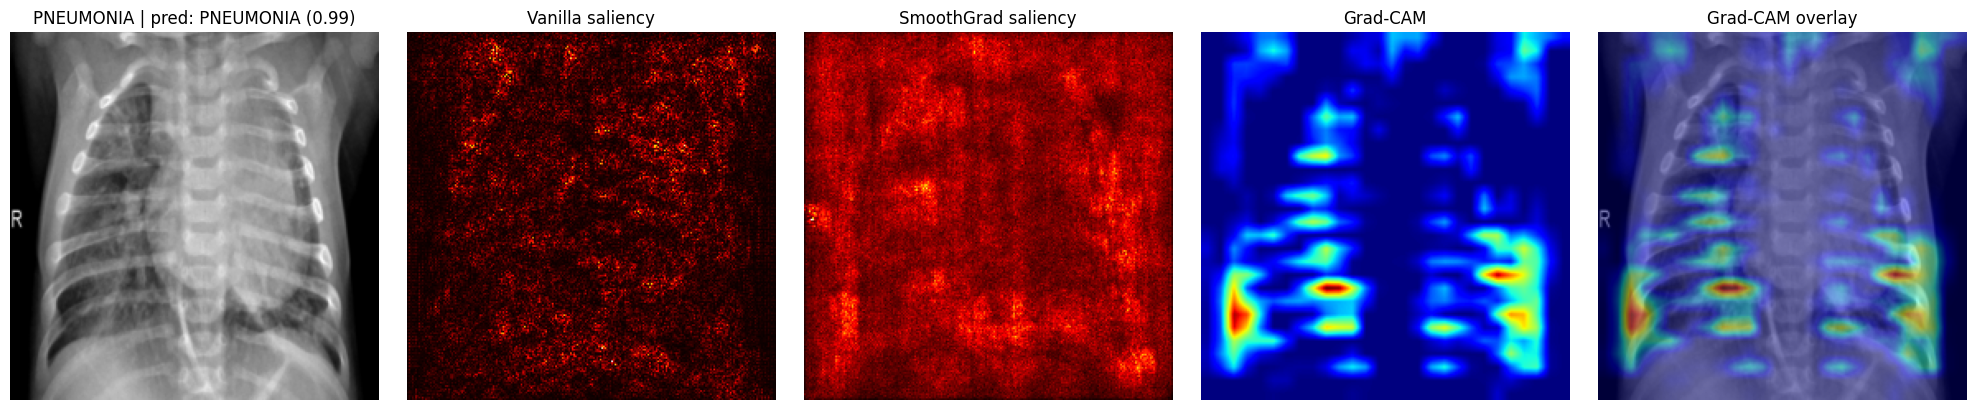

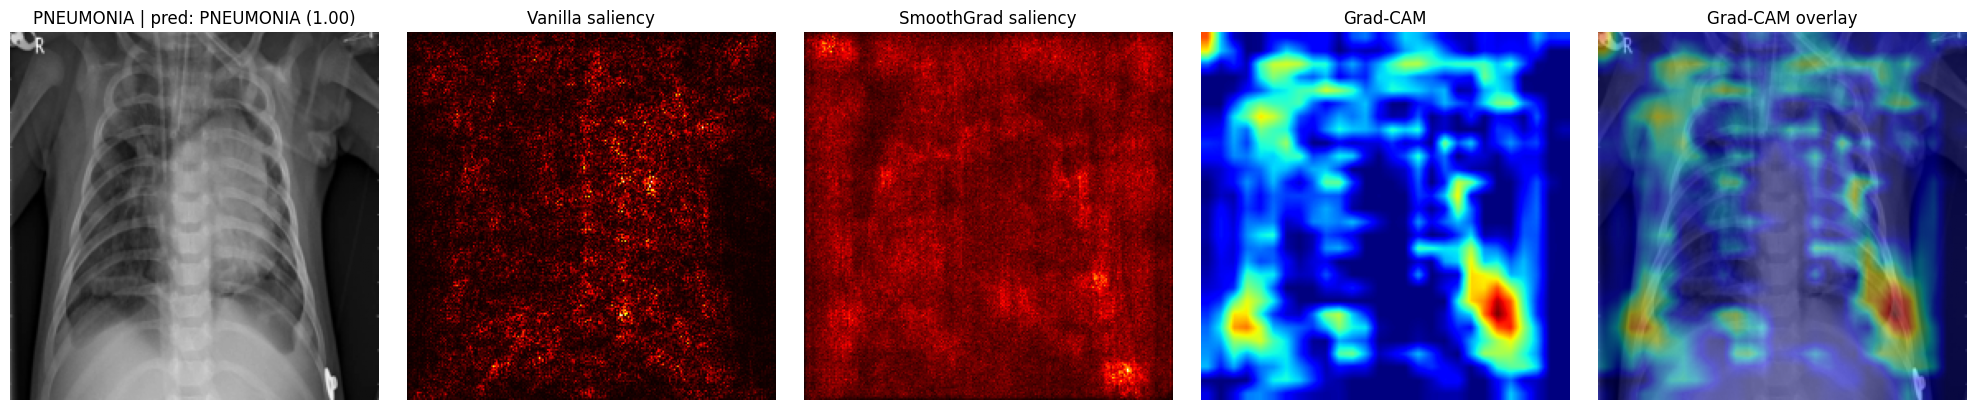

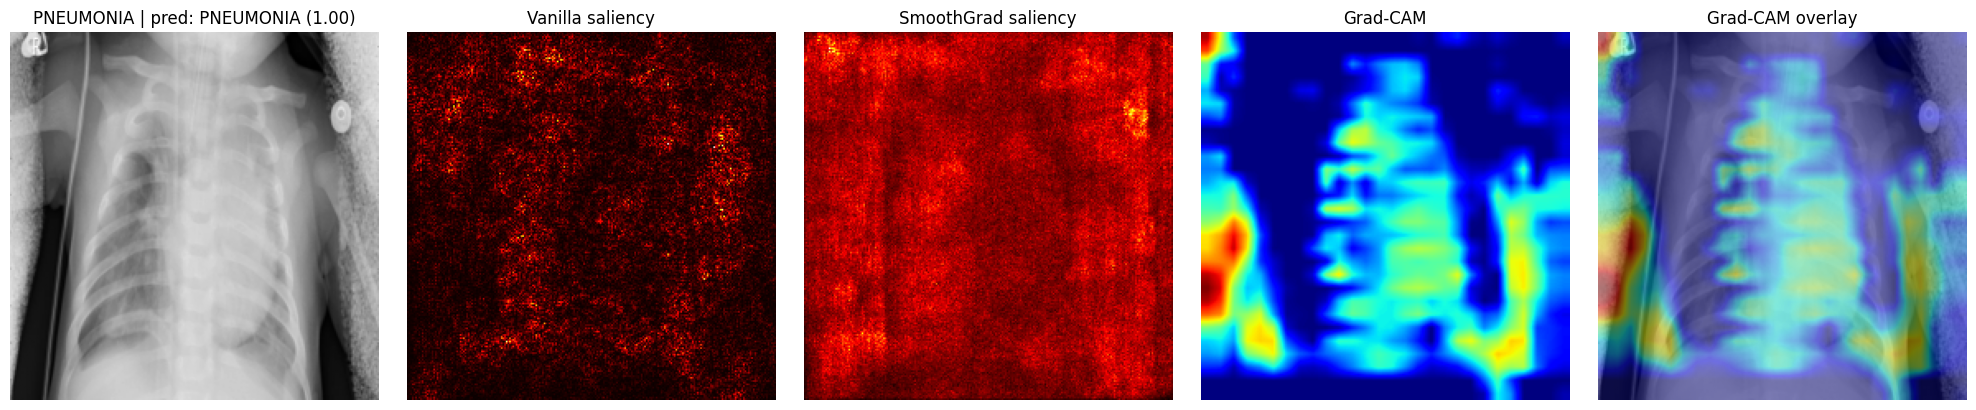

In [12]:
def vanilla_saliency(x, cls=None):
    model.eval(); x = x.clone().requires_grad_(True)
    out = model(x)
    cls = out.argmax(1).item() if cls is None else cls
    model.zero_grad(); out[0, cls].backward()
    sal = x.grad.abs()[0, 0].cpu().numpy()
    sal = (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)
    return sal, cls, F.softmax(out, 1)[0].detach().cpu()

def smooth_saliency(x, cls=None, n=20, sigma=0.15):
    maps = []
    for _ in range(n):
        noisy = x + sigma * torch.randn_like(x)
        s, c, _ = vanilla_saliency(noisy, cls); maps.append(s)
    s = np.mean(maps, 0); return (s - s.min()) / (s.max() - s.min() + 1e-8)

def grad_cam(x, cls=None):
    model.eval(); store = {}
    def fwd(m, i, o):
        store["a"] = o; o.register_hook(lambda g: store.__setitem__("g", g))
    h = model.block4[2].register_forward_hook(fwd)
    out = model(x)
    cls = out.argmax(1).item() if cls is None else cls
    model.zero_grad(); out[0, cls].backward(); h.remove()
    wts = store["g"].mean((2, 3), keepdim=True)
    cam = F.relu((wts * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), cls

def show_saliency(label, k, name):
    x = get_sample(label, k)
    img = x[0, 0].cpu().numpy() * 0.5 + 0.5
    sal, cls, probs = vanilla_saliency(x)
    ssal = smooth_saliency(x, cls)
    cam, _ = grad_cam(x, cls)
    fig, ax = plt.subplots(1, 5, figsize=(20, 4))
    ax[0].imshow(img, cmap="gray"); ax[0].set_title(f"{name} | pred: {classes[cls]} ({probs[cls]:.2f})")
    ax[1].imshow(sal, cmap="hot"); ax[1].set_title("Vanilla saliency")
    ax[2].imshow(ssal, cmap="hot"); ax[2].set_title("SmoothGrad saliency")
    ax[3].imshow(cam, cmap="jet"); ax[3].set_title("Grad-CAM")
    ax[4].imshow(img, cmap="gray"); ax[4].imshow(cam, cmap="jet", alpha=0.45); ax[4].set_title("Grad-CAM overlay")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

for k in range(3): show_saliency(0, k, "NORMAL")
for k in range(3): show_saliency(1, k, "PNEUMONIA")

89 misclassified test images; showing up to 4


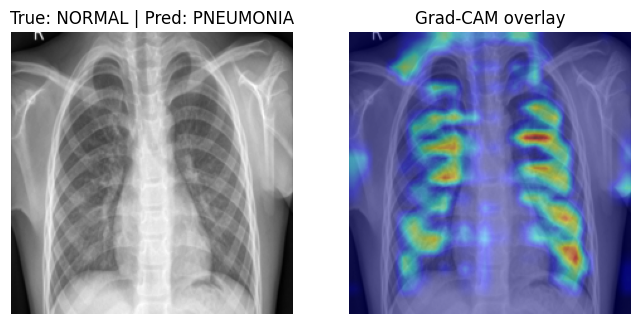

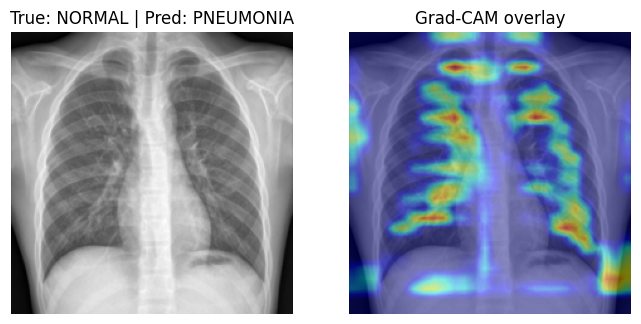

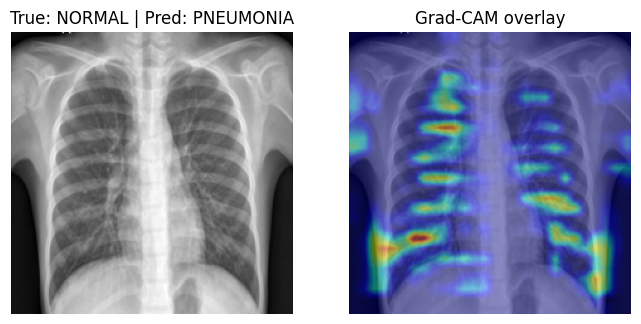

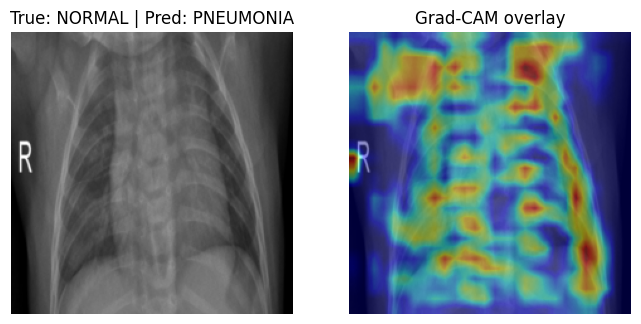

In [13]:
# Where does the model look on MISCLASSIFIED images?
wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} misclassified test images; showing up to 4")
for i in wrong[:4]:
    x = test_ds[i][0].unsqueeze(0).to(device)
    img = x[0, 0].cpu().numpy() * 0.5 + 0.5
    cam, cls = grad_cam(x)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(img, cmap="gray"); ax[0].set_title(f"True: {classes[y_true[i]]} | Pred: {classes[cls]}")
    ax[1].imshow(img, cmap="gray"); ax[1].imshow(cam, cmap="jet", alpha=0.45); ax[1].set_title("Grad-CAM overlay")
    for a in ax: a.axis("off")
    plt.show()

## 6. Observations and Conclusions

In [14]:
print("=== RESULT SUMMARY ===")
print(f"Best val loss        : {min(history['val_loss']):.4f}")
print(f"Final train / val acc: {history['train_acc'][-1]:.4f} / {history['val_acc'][-1]:.4f}")
print(f"Test accuracy        : {accuracy_score(y_true, y_pred):.4f}")
print(f"Test recall (PNEUM.) : {recall_score(y_true, y_pred):.4f}")
print(f"Test precision       : {precision_score(y_true, y_pred):.4f}")
print(f"Test ROC-AUC         : {roc_auc_score(y_true, y_prob):.4f}")
tn, fp, fn, tp = cm.ravel()
print(f"TP={tp}  TN={tn}  FP={fp}  FN={fn}")

=== RESULT SUMMARY ===
Best val loss        : 0.0864
Final train / val acc: 0.9411 / 0.9501
Test accuracy        : 0.8574
Test recall (PNEUM.) : 0.9872
Test precision       : 0.8209
Test ROC-AUC         : 0.9515
TP=385  TN=150  FP=84  FN=5
